# Anime Recommender

User-based collaborative filtering, content-based filtering, a weighted hybrid and Surprise SVD, built on AniList user ratings and evaluated against simple baselines on a shared held-out test set.

The ratings are collected by `anilist_ingestion.ipynb` and anonymised by `scripts/anonymise_users.py`. See `README.md` for how the users were sampled and the biases that come with it. Run from the repo root with the `anime-recommender` environment.

In [96]:
import json
import subprocess
import sys
import warnings
from dataclasses import dataclass
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from joblib import Parallel, delayed
from scipy.stats import iqr
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from surprise import SVD, Dataset, Reader, accuracy

warnings.filterwarnings("ignore")

In [97]:
DATA_RAW = Path("data/raw/anilist_anonymised")
DATA_PROCESSED = Path("data/processed")
ARTIFACTS = Path("artifacts")
FIGURES = Path("figures")

for folder in (DATA_PROCESSED, ARTIFACTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EXAMPLE_USER = "Kjarr"  # user ID for the example recommendations; None picks the first manual user (or the first user)

# AniList scores (1-100) are rescaled to 1-10, so ratings go down to 0.1
RATING_MIN, RATING_MAX = 0.1, 10.0

## Load ratings

`ratings.csv.gz` has one row per list entry. Entries without a score (planned, dropped, or watched but not scored) are not ratings, so only rated entries are kept. `source` is `seed` for sampled users and `manual` for people of interest added by name.

In [98]:
ratings_all = pd.read_csv(DATA_RAW / "ratings.csv.gz", dtype={"user_id": str})
anime_meta = pd.read_csv(DATA_RAW / "anime_metadata.csv").drop_duplicates("anime_ID").reset_index(drop=True)
print(f"{len(ratings_all)} list entries from {ratings_all['user_id'].nunique()} users, {ratings_all['is_rated'].mean():.1%} of them rated")

ratings_long = ratings_all.loc[ratings_all["is_rated"], ["user_id", "source", "anime_id", "rating"]].reset_index(drop=True)
assert not ratings_long.duplicated(["user_id", "anime_id"]).any()

print(f"{ratings_long['user_id'].nunique()} users rated {ratings_long['anime_id'].nunique()} anime")
print("Users by source:", ratings_long.drop_duplicates("user_id")["source"].value_counts().to_dict())
ratings_long.head()

7485213 list entries from 9467 users, 60.9% of them rated
9459 users rated 20700 anime
Users by source: {'seed': 9458, 'manual': 1}


,user_id,source,anime_id,rating
0,anon-00596,seed,6682,6.0
1,anon-00596,seed,21366,10.0
2,anon-00596,seed,98478,10.0
3,anon-00596,seed,100526,7.0
4,anon-00596,seed,99725,8.0


# EDA

## Matrix Sparsity

In [99]:
def sparsity(df):
    """Share of the user x anime matrix with no rating."""
    return 1 - len(df) / (df["user_id"].nunique() * df["anime_id"].nunique())


print(f"Sparsity of the matrix: {sparsity(ratings_long):.2%}")

Sparsity of the matrix: 97.67%


## Filtering based on stats (mean and median)

Users with few ratings and rarely rated anime carry little information for the similarity calculations. Manual users are kept whatever their counts, so they still get recommendations.

In [100]:
MIN_RATINGS_PER_USER = 85
MIN_RATINGS_PER_ANIME = 25

user_counts = ratings_long["user_id"].value_counts()
anime_counts = ratings_long["anime_id"].value_counts()

manual_users = set(ratings_long.loc[ratings_long["source"] == "manual", "user_id"])
keep_users = set(user_counts.index[user_counts >= MIN_RATINGS_PER_USER]) | manual_users
keep_anime = anime_counts.index[anime_counts >= MIN_RATINGS_PER_ANIME]
filtered_data = ratings_long[ratings_long["user_id"].isin(keep_users) & ratings_long["anime_id"].isin(keep_anime)]

filtered_user_counts = filtered_data["user_id"].value_counts()
filtered_anime_counts = filtered_data["anime_id"].value_counts()


def count_summary(df, user_counts, anime_counts):
    return {
        "Users": len(user_counts),
        "Anime": len(anime_counts),
        "Ratings": len(df),
        "Mean ratings per user": user_counts.mean(),
        "Median ratings per user": user_counts.median(),
        "Mean ratings per anime": anime_counts.mean(),
        "Median ratings per anime": anime_counts.median(),
    }


pd.DataFrame({
    "Raw": count_summary(ratings_long, user_counts, anime_counts),
    "Filtered": count_summary(filtered_data, filtered_user_counts, filtered_anime_counts),
}).round(1)

,Raw,Filtered
Users,9459.0,8503.0
Anime,20700.0,10704.0
Ratings,4557327.0,4427738.0
Mean ratings per user,481.8,520.7
Median ratings per user,343.0,383.0
Mean ratings per anime,220.2,413.7
Median ratings per anime,27.0,129.0


#### Rating counts before and after filtering

The x-axis stops at the 1.5×IQR outlier threshold, since a few power users and very popular anime have long tails.

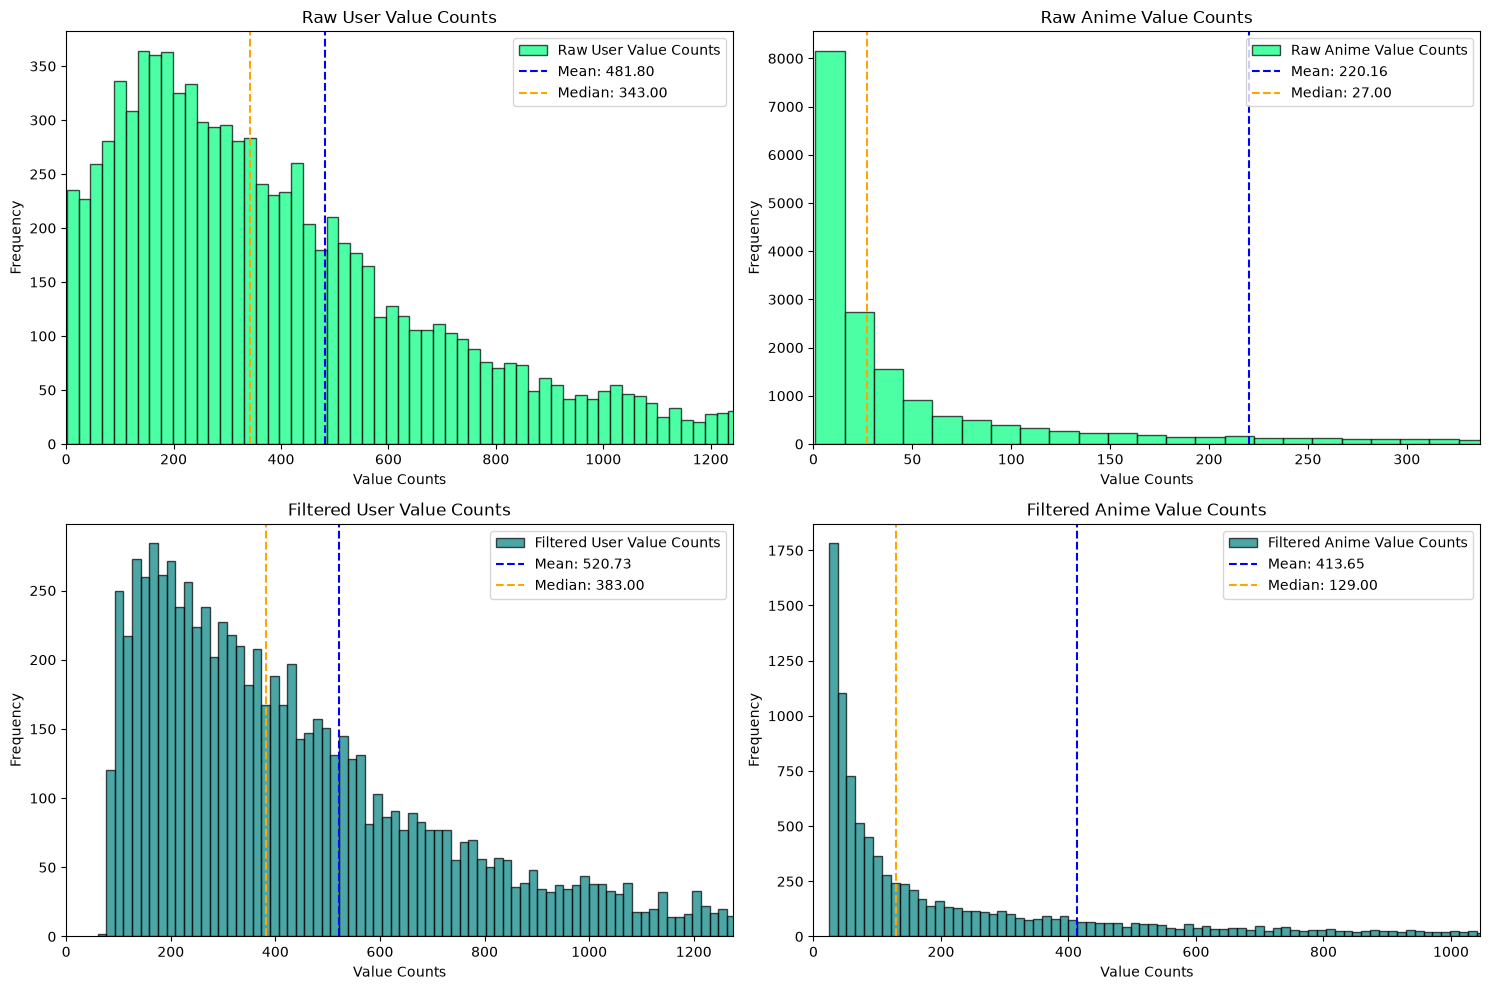

In [101]:
panels = [
    ("Raw User Value Counts", user_counts, "springgreen"),
    ("Raw Anime Value Counts", anime_counts, "springgreen"),
    ("Filtered User Value Counts", filtered_user_counts, "teal"),
    ("Filtered Anime Value Counts", filtered_anime_counts, "teal"),
]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, (title, counts, color) in zip(axes.flat, panels):
    mean, median = np.mean(counts), np.median(counts)
    outlier_threshold = np.percentile(counts, 75) + 1.5 * iqr(counts)

    ax.hist(counts, bins=500, edgecolor="k", alpha=0.7, color=color, label=title)
    ax.axvline(mean, color="blue", linestyle="--", label=f"Mean: {mean:.2f}")
    ax.axvline(median, color="orange", linestyle="--", label=f"Median: {median:.2f}")
    ax.set(title=title, xlabel="Value Counts", ylabel="Frequency", xlim=(0, outlier_threshold))
    ax.legend()

plt.tight_layout()
plt.savefig(FIGURES / "anime_user_mean_median.png")
plt.show()

## Mean data exploration

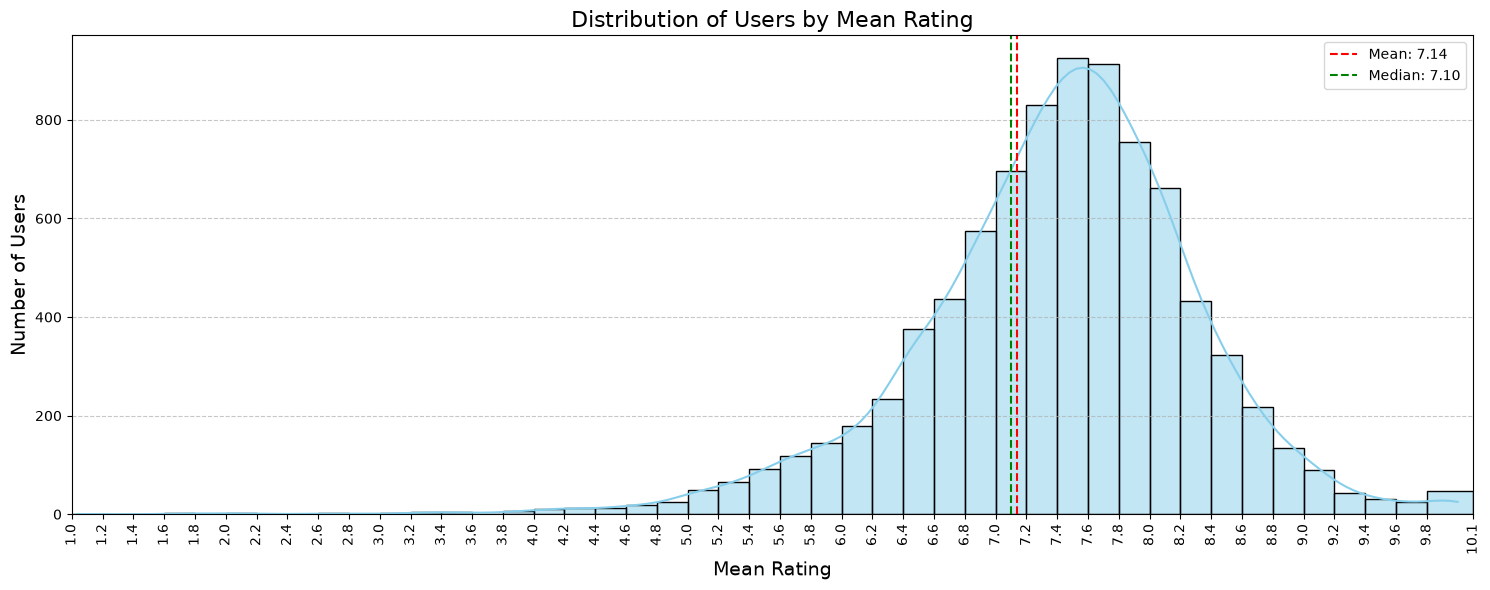

In [102]:
user_mean_ratings = filtered_data.groupby("user_id")["rating"].mean()
overall_mean, overall_median = filtered_data["rating"].mean(), filtered_data["rating"].median()

bins = np.append(np.arange(1, 10, 0.2), 10.1)  # 1 to 10 in steps of 0.2

plt.figure(figsize=(15, 6))
sns.histplot(user_mean_ratings, bins=bins, kde=True, color="skyblue", edgecolor="black")
plt.axvline(overall_mean, color="r", linestyle="--", label=f"Mean: {overall_mean:.2f}")
plt.axvline(overall_median, color="g", linestyle="--", label=f"Median: {overall_median:.2f}")

plt.title("Distribution of Users by Mean Rating", fontsize=16)
plt.xlabel("Mean Rating", fontsize=14)
plt.ylabel("Number of Users", fontsize=14)
plt.xticks(bins, rotation=90, fontsize=10)
plt.xlim(1, 10.1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.savefig(FIGURES / "mean_rating_distribution.png")
plt.show()

In [103]:
# Rating nearly everything 9-10 says little about taste, so those users are removed. Manual users are kept.
MAX_MEAN_RATING = 9.0

users_to_remove = user_mean_ratings.index[(user_mean_ratings > MAX_MEAN_RATING) & ~user_mean_ratings.index.isin(manual_users)]
filtered_ratings = filtered_data[~filtered_data["user_id"].isin(users_to_remove)]

print(f"Users: {filtered_data['user_id'].nunique()} -> {filtered_ratings['user_id'].nunique()}")
print(f"Mean of user mean ratings: {user_mean_ratings.mean():.3f} -> {filtered_ratings.groupby('user_id')['rating'].mean().mean():.3f}")

Users: 8503 -> 8276
Mean of user mean ratings: 7.401 -> 7.345


### Recalc Sparsity

In [104]:
print(f"Sparsity of the matrix after filtering: {sparsity(filtered_ratings):.2%}")

Sparsity of the matrix after filtering: 95.09%


### Save processed ratings

In [105]:
filtered_ratings[["user_id", "source", "anime_id", "rating"]].to_csv(DATA_PROCESSED / "ratings_long_filtered.csv", index=False)

## Sample vs all AniList users

AniList publishes each anime's score distribution across all of its users, in 10-point buckets. Summing it over the anime in the filtered sample shows how AniList as a whole rates those same anime. The sample's ratings are rounded to the nearest whole point for the comparison, so the statistics are approximate. The two sides weight each anime by how often that group rated it. Manual users are left out, since they were not sampled.

10704 of 10704 sampled anime have a published score distribution
Exact sample mean (unrounded): 7.10


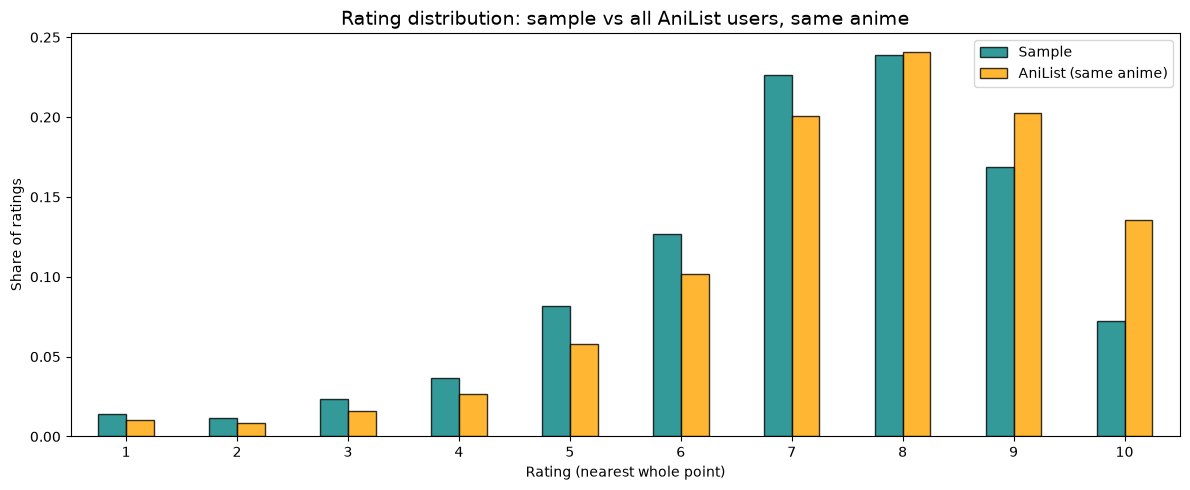

,Sample,AniList (same anime)
Users,8275.00,NaN
Ratings,4345691.00,1.235710e+08
Mean,7.15,7.590000e+00
Median,7.00,8.000000e+00
Standard Deviation,1.87,1.820000e+00
Skewness,-0.90,-1.000000e+00
Kurtosis,0.92,1.290000e+00
Range,9.00,9.000000e+00


In [106]:
def weighted_rating_stats(ratings, counts):
    """Mean, median, standard deviation, skewness, excess kurtosis and range of ratings given as a frequency table."""
    ratings = np.asarray(ratings, dtype=float)
    counts = np.asarray(counts, dtype=float)
    n = counts.sum()

    mean = (ratings * counts).sum() / n
    central = ratings - mean
    m2, m3, m4 = ((counts * central**p).sum() / n for p in (2, 3, 4))

    order = np.argsort(ratings)
    median = ratings[order][np.searchsorted(np.cumsum(counts[order]), n / 2)]

    return {
        "Mean": mean,
        "Median": median,
        "Standard Deviation": np.sqrt(m2),
        "Skewness": m3 / m2**1.5,
        "Kurtosis": m4 / m2**2 - 3,
        "Range": ratings.max() - ratings.min(),
    }


sample = filtered_ratings[filtered_ratings["source"] == "seed"]
rating_points = np.arange(1, 11)

# Sample ratings rounded to the nearest whole point
sample_counts = np.clip(np.floor(sample["rating"] + 0.5), 1, 10).value_counts().reindex(rating_points, fill_value=0)

# AniList-wide score counts for the same anime (buckets 10..100 -> 1..10)
in_sample = anime_meta[anime_meta["anime_ID"].isin(sample["anime_id"])]
population_counts = pd.Series(0.0, index=rating_points)
for distribution in in_sample["score_distribution"].dropna():
    for bucket, amount in json.loads(distribution).items():
        population_counts[int(bucket) // 10] += amount

print(f"{len(in_sample)} of {sample['anime_id'].nunique()} sampled anime have a published score distribution")
print(f"Exact sample mean (unrounded): {sample['rating'].mean():.2f}")

shares = pd.DataFrame({
    "Sample": sample_counts / sample_counts.sum(),
    "AniList (same anime)": population_counts / population_counts.sum(),
})
ax = shares.plot.bar(figsize=(12, 5), color=["teal", "orange"], edgecolor="black", alpha=0.8, rot=0)
ax.set_title("Rating distribution: sample vs all AniList users, same anime", fontsize=14)
ax.set(xlabel="Rating (nearest whole point)", ylabel="Share of ratings")
plt.tight_layout()
plt.savefig(FIGURES / "sample_vs_anilist_ratings.png")
plt.show()

pd.DataFrame({
    "Sample": {"Users": sample["user_id"].nunique(), "Ratings": len(sample), **weighted_rating_stats(rating_points, sample_counts)},
    "AniList (same anime)": {"Users": np.nan, "Ratings": population_counts.sum(), **weighted_rating_stats(rating_points, population_counts)},
}).round(2)

## User profile correlations

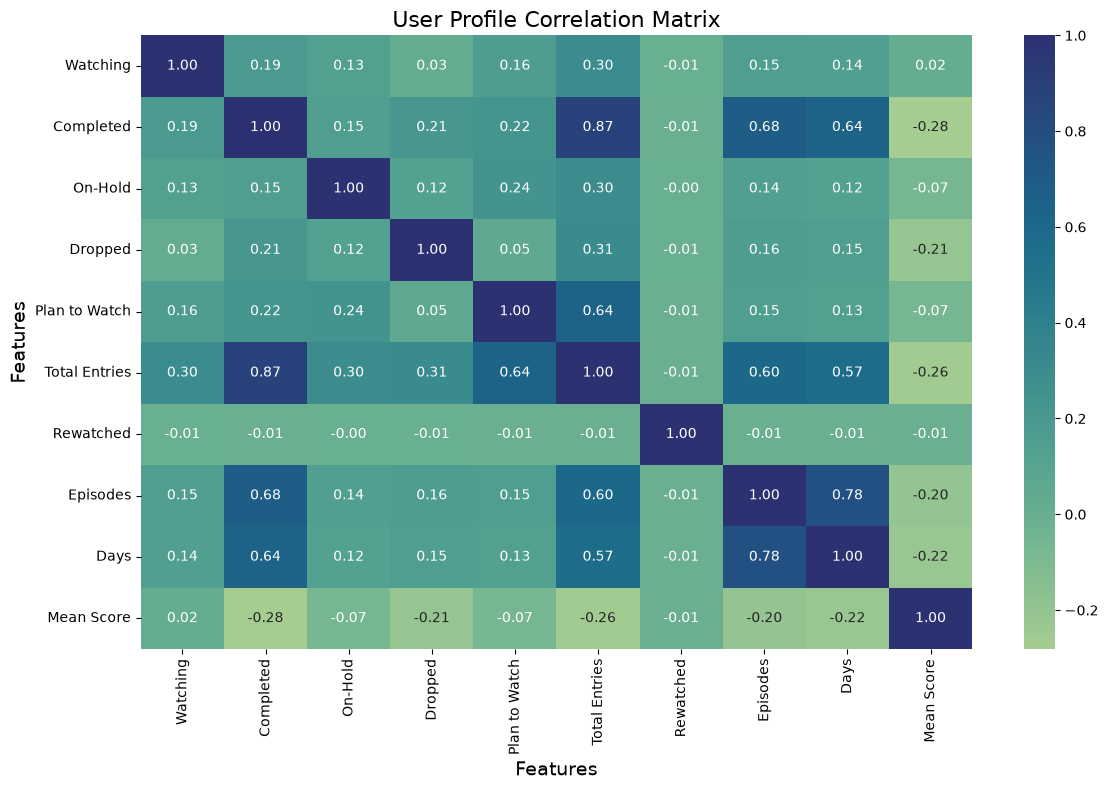

In [107]:
user_data = pd.read_csv(DATA_RAW / "user_profiles.csv", dtype={"user": str})

# List statistics of the sampled users. AniList doesn't expose gender, so that column is empty and dropped.
seed_profiles = user_data[user_data["source"] == "seed"].drop(columns=["Gender"])
correlation_matrix = seed_profiles.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="crest", fmt=".2f", cbar=True)

plt.title("User Profile Correlation Matrix", fontsize=16)
plt.xlabel("Features", fontsize=14)
plt.ylabel("Features", fontsize=14)

plt.tight_layout()
plt.savefig(FIGURES / "feature_matrix.png")
plt.show()

# Model Building

## Train / validation / test split

Every model is scored on the same held-out test set (20% of each user's ratings). Hyperparameters (neighbourhood sizes, hybrid weight) are tuned on a validation split carved out of the training data, so the test set is only used for the final scores.

In [108]:
def stratified_split(data, test_size=0.2, random_state=RANDOM_STATE):
    """Split each user's ratings into train/test so every user appears in both."""
    train_parts, test_parts = [], []
    for _, user_ratings in data.groupby("user_id"):
        if len(user_ratings) < 2:  # e.g. a manual user with a single rating: training only
            train_parts.append(user_ratings)
            continue
        train, test = train_test_split(user_ratings, test_size=test_size, random_state=random_state)
        train_parts.append(train)
        test_parts.append(test)
    return pd.concat(train_parts), pd.concat(test_parts)


ratings = pd.read_csv(DATA_PROCESSED / "ratings_long_filtered.csv", dtype={"user_id": str})

train_df, test_df = stratified_split(ratings)
tune_df, val_df = stratified_split(train_df)

if EXAMPLE_USER is None:
    manual = sorted(ratings.loc[ratings["source"] == "manual", "user_id"].unique())
    EXAMPLE_USER = manual[0] if manual else ratings["user_id"].iloc[0]

print(f"Train: {len(train_df)} ratings (tune {len(tune_df)} + validation {len(val_df)}), test: {len(test_df)} ratings")
print(f"Example user for recommendations: {EXAMPLE_USER}")

Train: 3473367 ratings (tune 2775421 + validation 697946), test: 872455 ratings
Example user for recommendations: Kjarr


## Rating matrices and evaluation helpers

In [109]:
# Fixed user and anime orderings so every matrix lines up
user_index = pd.Index(np.sort(ratings["user_id"].unique()), name="user_id")
anime_index = pd.Index(np.sort(ratings["anime_id"].unique()), name="anime_id")
anime_titles = anime_meta.set_index("anime_ID")["Title"]


def rating_matrix(df):
    """Dense user x anime matrix of ratings, NaN where the user has not rated the anime."""
    R = np.full((len(user_index), len(anime_index)), np.nan, dtype=np.float32)
    R[user_index.get_indexer(df["user_id"]), anime_index.get_indexer(df["anime_id"])] = df["rating"].to_numpy()
    return R


def pair_indices(df):
    """Row/column positions and true ratings of the (user, anime) pairs in df."""
    return user_index.get_indexer(df["user_id"]), anime_index.get_indexer(df["anime_id"]), df["rating"].to_numpy()


def score(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))}


R_full, R_train, R_tune = rating_matrix(ratings), rating_matrix(train_df), rating_matrix(tune_df)
test_users, test_items, y_test = pair_indices(test_df)
val_users, val_items, y_val = pair_indices(val_df)

# One row per model: test MAE, RMSE and coverage (the share of test ratings the model
# predicted itself rather than falling back to the baseline)
results = []


def add_result(model, preds, support=None):
    """Score test-set predictions and add them to the results table. support: neighbours behind each prediction."""
    coverage = 1.0 if support is None else (support > 0).mean()
    results.append({"Model": model, **score(y_test, preds), "Coverage": coverage})
    return results[-1]


def tune_k(predict, ks):
    """
    Validation scores for each neighbourhood size k. predict(users, items, k) returns (predictions, support).
    Returns the table and the k with the lowest RMSE.
    """
    rows = []
    for k in ks:
        preds, support = predict(val_users, val_items, k)
        rows.append({"k": k, **score(y_val, preds), "Coverage": (support > 0).mean()})
    table = pd.DataFrame(rows)
    return table, int(table.loc[table["RMSE"].idxmin(), "k"])


def recommend(user_id, R, predict, n_recommendations=10, min_support=5):
    """
    Top-N anime the user has not rated, ranked by predicted rating.

    `predict(users, items)` returns the predictions, or (predictions, support) for the kNN models,
    where support is the number of neighbours behind each prediction. Anime with fewer than
    `min_support` neighbours are skipped so one enthusiastic neighbour cannot put an anime at the top.
    """
    u = user_index.get_loc(user_id)
    unrated = np.flatnonzero(np.isnan(R[u]))
    out = predict(np.full(len(unrated), u), unrated)
    preds, support = out if isinstance(out, tuple) else (out, None)

    ids = anime_index[unrated]
    recs = pd.DataFrame({
        "Anime ID": ids,
        "Anime Title": [anime_titles.get(a, f"AniList #{a}") for a in ids],
        "Predicted Rating": preds,
    })
    sort_by = ["Predicted Rating"]
    if support is not None:
        recs["Neighbours"] = support
        recs = recs[recs["Neighbours"] >= min_support]
        sort_by.append("Neighbours")
    return recs.sort_values(sort_by, ascending=False).head(n_recommendations).reset_index(drop=True)

## Baselines

Any recommender has to beat these to be worth using. The user mean + item bias baseline is also what the kNN models build on: they predict how far a user's rating will land from it (the kNN-baseline approach), and fall back to it when they have no neighbours.

In [110]:
@dataclass
class Baseline:
    """User mean + item bias baseline fitted on a rating matrix, and every rating's distance from it."""
    user_means: np.ndarray
    item_bias: np.ndarray
    user_std: np.ndarray   # each user's spread of ratings around the baseline
    residuals: np.ndarray  # (rating - baseline) / user_std, NaN where unrated

    def predict(self, users, items):
        return self.user_means[users] + self.item_bias[items]


def fit_baseline(R, item_reg=10, min_std=0.5):
    """
    The item bias is how far above their own mean users rate the anime on average,
    shrunk towards 0 for anime with few ratings (item_reg acts like extra ratings of 0).
    user_std is floored at min_std so users who give almost everything the same score
    don't get huge normalised residuals.
    """
    user_means = np.nanmean(R, axis=1)
    deviations = R - user_means[:, None]
    n_ratings = (~np.isnan(R)).sum(axis=0)
    item_bias = np.nansum(deviations, axis=0) / (n_ratings + item_reg)
    user_std = np.maximum(np.sqrt(np.nanmean((deviations - item_bias[None, :]) ** 2, axis=1)), min_std)
    residuals = ((R - user_means[:, None] - item_bias[None, :]) / user_std[:, None]).astype(np.float32)
    return Baseline(user_means, item_bias, user_std, residuals)


base_train = fit_baseline(R_train)
base_tune = fit_baseline(R_tune)
global_mean = np.nanmean(R_train)

baseline_predictions = {
    "Global mean": np.full(len(y_test), global_mean),
    "User mean": base_train.user_means[test_users],
    "User mean + item bias": np.clip(base_train.predict(test_users, test_items), RATING_MIN, RATING_MAX),
}
for name, preds in baseline_predictions.items():
    add_result(name, preds)

pd.DataFrame(results)

,Model,MAE,RMSE,Coverage
0,Global mean,1.413995,1.859413,1.0
1,User mean,1.194061,1.585216,1.0
2,User mean + item bias,0.996624,1.346609,1.0


## Collaborative Filtering (user-based kNN)

- **Predictions build on the baseline** (kNN-baseline): the prediction is the user mean + item bias baseline plus the neighbours' average deviation from *their* baselines. So neighbours only explain what the baseline doesn't, instead of re-learning that an anime is popular.
- **Per-user normalisation**: each neighbour's deviation is divided by their own rating spread and multiplied by the target user's, so a harsh rater's "+1" and a generous rater's "+2" are put on the same footing. (AniList users score on different scales, all converted to 1-100.)
- **Similarity** is cosine over the anime *both* users rated, on those baseline residuals. Similarities can be negative, and unrated anime stay missing instead of being filled with 0.
- **Small overlaps are distrusted**: similarities are multiplied by `n_shared / (n_shared + 25)` and pairs sharing fewer than 5 anime are ignored.
- **Neighbours are chosen per anime** from the users who actually rated it. Pairs with no qualifying neighbour fall back to the baseline, and the share of pairs the model predicted itself is reported as coverage.

### Functions

In [111]:
def user_similarity_matrix(Z, shrinkage=25, min_overlap=5):
    """
    Cosine similarity between every pair of users over the anime both rated, computed on their
    normalised residuals (ratings minus the baseline, divided by the user's spread). Removing the
    item bias means two users don't look alike just because they both like popular anime; the
    per-user scaling cancels out in a cosine but matters in the predictions.
    Similarities are shrunk towards 0 when the overlap is small and zeroed below min_overlap.
    """
    rated = ~np.isnan(Z)
    X = np.where(rated, Z, 0).astype(np.float32)
    M = rated.astype(np.float32)

    dot = X @ X.T                    # unrated entries are 0, so this sums over co-rated anime only
    sq_norms = (X ** 2) @ M.T        # [u, v] = sum of u's squared residuals over anime v also rated
    n_shared = M @ M.T

    with np.errstate(divide="ignore", invalid="ignore"):
        sim = dot / np.sqrt(sq_norms * sq_norms.T)
    sim = np.nan_to_num(sim) * (n_shared / (n_shared + shrinkage))
    sim[n_shared < min_overlap] = 0
    np.fill_diagonal(sim, 0)
    return sim.astype(np.float32)


def top_k_average(similarities, values, k):
    """
    For each row of `similarities` (one row per prediction, one column per candidate neighbour), the
    similarity-weighted average of `values` over the k most similar neighbours. Negative similarities
    count as 0. Returns the averages (NaN where no neighbour has a positive similarity) and the number
    of neighbours with a positive similarity behind each one.
    """
    S = np.maximum(similarities, 0)
    n = min(k, S.shape[1])
    top = np.argpartition(-S, n - 1, axis=1)[:, :n]
    weights = np.take_along_axis(S, top, axis=1)
    with np.errstate(divide="ignore", invalid="ignore"):
        averages = (weights * values[top]).sum(axis=1) / weights.sum(axis=1)
    return averages, (weights > 0).sum(axis=1)


def predict_user_knn(base, sim, users, items, k=30):
    """
    Predict ratings for (user, anime) pairs with user-based kNN on top of the baseline.

    For each anime, the neighbours are the k users most similar to the target user among
    those who rated it. The prediction is the target's baseline plus their rating spread times
    the similarity-weighted average of the neighbours' normalised residuals.
    Pairs with no neighbour get the baseline.

    Returns the predictions and the number of neighbours behind each one (0 = baseline).
    """
    preds = base.predict(users, items)
    support = np.zeros(len(users), dtype=int)

    for item, positions in pd.Series(items).groupby(items).indices.items():
        raters = np.flatnonzero(~np.isnan(base.residuals[:, item]))
        if len(raters) == 0:
            continue
        target_users = users[positions]
        averages, n_neighbours = top_k_average(sim[np.ix_(target_users, raters)], base.residuals[raters, item], k)

        found = n_neighbours > 0
        preds[positions[found]] += base.user_std[target_users[found]] * averages[found]
        support[positions] = n_neighbours

    return np.clip(preds, RATING_MIN, RATING_MAX), support

### Tune neighbourhood size on the validation set

In [112]:
sim_tune = user_similarity_matrix(base_tune.residuals)
cf_tuning, best_cf_k = tune_k(lambda users, items, k: predict_user_knn(base_tune, sim_tune, users, items, k), [5, 10, 20, 30, 50, 100])
print(f"Best k: {best_cf_k}")
cf_tuning

Best k: 50


,k,MAE,RMSE,Coverage
0,5,0.940621,1.290508,1.0
1,10,0.903823,1.242140,1.0
2,20,0.887757,1.221109,1.0
3,30,0.884447,1.216443,1.0
4,50,0.884535,1.215873,1.0
5,100,0.888942,1.220053,1.0


### Evaluation

In [113]:
# Similarities from training ratings only, so no test rating influences the neighbourhoods
sim_train = user_similarity_matrix(base_train.residuals)

cf_test_preds, cf_test_support = predict_user_knn(base_train, sim_train, test_users, test_items, k=best_cf_k)
add_result(f"User-based CF (k={best_cf_k})", cf_test_preds, cf_test_support)

{'Model': 'User-based CF (k=50)',
 'MAE': 0.8799636638771958,
 'RMSE': np.float64(1.210565137983393),
 'Coverage': np.float64(1.0)}

#### Visualise similarity distribution

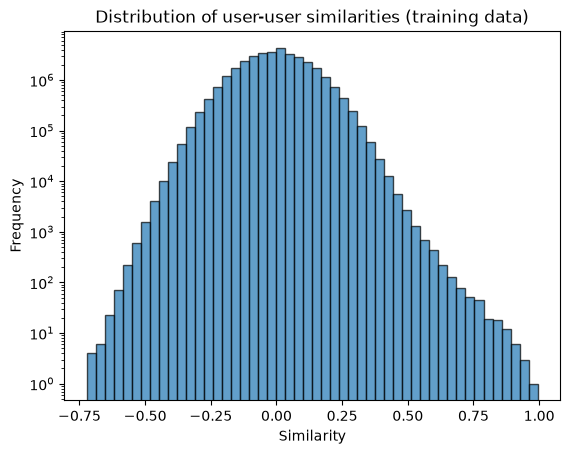

Negative: 49.7%, zero: 2.2%, max: 0.994


In [114]:
pair_similarities = sim_train[np.triu_indices_from(sim_train, k=1)]

plt.hist(pair_similarities, bins=50, edgecolor="k", alpha=0.7)
plt.title("Distribution of user-user similarities (training data)")
plt.xlabel("Similarity")
plt.ylabel("Frequency")
plt.yscale("log")
plt.show()

print(f"Negative: {(pair_similarities < 0).mean():.1%}, zero: {(pair_similarities == 0).mean():.1%}, max: {pair_similarities.max():.3f}")

## Content-based Filtering

- **Predictions build on the baseline** (kNN-baseline): the user mean + item bias baseline plus the similarity-weighted average of the user's own deviations from the baseline on the *k* most similar anime they have rated (item-based kNN on content similarity). Taking the item bias into account is what the previous version lacked: it adjusted the user's mean using only their own ratings, and ignored how each anime is rated overall.
- **Neighbours come from everything the user rated**, not only the target's stored top 5 similar anime, so far more pairs can be predicted.
- **Anime without metadata fall back to the baseline** (metadata covers the 15,000 anime rated most often in the collection), and coverage is reported so the error is comparable with the other models.
- Similarities are computed in one vectorised call and kept as a matrix. The top 15 similar anime per anime are saved to `artifacts/anime_similarity_top15.csv` for inspection.

### Preprocessing and Model Build

In [115]:
has_metadata = anime_index.isin(anime_meta["anime_ID"])
print(f"{has_metadata.sum()} of {len(anime_index)} rated anime have metadata ({has_metadata.mean():.1%})")
print(f"{has_metadata[test_items].mean():.1%} of test ratings are for anime with metadata")

10704 of 10704 rated anime have metadata (100.0%)
100.0% of test ratings are for anime with metadata


In [116]:
# How much each feature group counts in the content similarity
FEATURE_WEIGHTS = {"episodes": 1.0, "type": 0.25, "genres": 2.5, "themes": 1.75, "synopsis": 3.0}


def split_labels(column):
    """Comma-separated labels to lists, with missing values as empty lists."""
    return column.fillna("").apply(lambda s: [label for label in s.split(", ") if label])


def load_synopsis_embeddings(anime_ids):
    """
    all-MiniLM-L6-v2 synopsis embeddings in the order of anime_ids, cached in artifacts/ with their anime IDs.
    The synopsis text itself isn't in the repo, only the embeddings. Encoding runs in a separate
    process.
    """
    embeddings_path = ARTIFACTS / "synopsis_embeddings.npy"
    ids_path = ARTIFACTS / "synopsis_embedding_ids.npy"
    if not (embeddings_path.exists() and ids_path.exists()):
        subprocess.run([sys.executable, "scripts/build_synopsis_embeddings.py"], check=True)
    positions = pd.Index(np.load(ids_path)).get_indexer(anime_ids)
    assert (positions >= 0).all(), "Cached embeddings are missing some anime: delete artifacts/synopsis_embeddings.npy to rebuild them"
    return np.load(embeddings_path)[positions]


features = {
    "episodes": StandardScaler().fit_transform(np.log1p(anime_meta[["Episode Count"]].fillna(0))),
    "type": OneHotEncoder(sparse_output=False).fit_transform(anime_meta[["Type"]].fillna("Unknown")),
    "genres": MultiLabelBinarizer().fit_transform(split_labels(anime_meta["Genre(s)"])),
    "themes": MultiLabelBinarizer().fit_transform(split_labels(anime_meta["Theme(s)"])),
    "synopsis": load_synopsis_embeddings(anime_meta["anime_ID"]),
}
combined_features = np.hstack([features[name] * weight for name, weight in FEATURE_WEIGHTS.items()])

# Cosine similarity between every pair of anime with metadata
content_sim = cosine_similarity(combined_features).astype(np.float32)

# The same similarities laid out on the rated-anime index (anime without metadata keep similarity 0)
meta_rows = pd.Index(anime_meta["anime_ID"]).get_indexer(anime_index)
with_meta = np.flatnonzero(meta_rows >= 0)
item_sim = np.zeros((len(anime_index), len(anime_index)), dtype=np.float32)
item_sim[np.ix_(with_meta, with_meta)] = content_sim[np.ix_(meta_rows[with_meta], meta_rows[with_meta])]
np.fill_diagonal(item_sim, 0)

In [117]:
def most_similar(sim, top_n, chunk=1000):
    """Column indices of the top_n most similar items for every row, excluding the item itself.
    Works through `chunk` rows at a time: sorting the whole matrix at once needs several GB."""
    top = np.empty((len(sim), top_n), dtype=np.int64)
    for start in range(0, len(sim), chunk):
        block = sim[start:start + chunk].copy()
        block[np.arange(len(block)), np.arange(start, start + len(block))] = -np.inf
        candidates = np.argpartition(-block, top_n, axis=1)[:, :top_n]
        order = np.argsort(-np.take_along_axis(block, candidates, axis=1), axis=1)
        top[start:start + chunk] = np.take_along_axis(candidates, order, axis=1)
    return top


# The 15 most similar anime for each anime, saved for inspection
TOP_N = 15
top_idx = most_similar(content_sim, TOP_N)
ids, titles = anime_meta["anime_ID"].to_numpy(), anime_meta["Title"].to_numpy()

similar_df = pd.DataFrame({
    "anime_id": np.repeat(ids, TOP_N),
    "anime_title": np.repeat(titles, TOP_N),
    "rank": np.tile(np.arange(1, TOP_N + 1), len(ids)),
    "similar_anime_id": ids[top_idx].ravel(),
    "similar_title": titles[top_idx].ravel(),
    "similarity": np.take_along_axis(content_sim, top_idx, axis=1).ravel(),
})
similar_df.to_csv(ARTIFACTS / "anime_similarity_top15.csv", index=False)
similar_df.head(TOP_N)

,anime_id,anime_title,rank,similar_anime_id,similar_title,similarity
0,16498,Shingeki no Kyojin,1,20958,Shingeki no Kyojin Season 2,0.814091
1,16498,Shingeki no Kyojin,2,99147,Shingeki no Kyojin Season 3,0.732531
2,16498,Shingeki no Kyojin,3,100465,Shingeki no Kyojin Season 2: Kakusei no Houkou,0.685874
3,16498,Shingeki no Kyojin,4,104578,Shingeki no Kyojin Season 3 Part 2,0.680818
4,16498,Shingeki no Kyojin,5,110277,Shingeki no Kyojin: The Final Season,0.646090
5,16498,Shingeki no Kyojin,6,18397,Shingeki no Kyojin OVA,0.628255
6,16498,Shingeki no Kyojin,7,131681,Shingeki no Kyojin: The Final Season Part 2,0.625920
7,16498,Shingeki no Kyojin,8,146984,Shingeki no Kyojin: The Final Season - Kankets...,0.620351
8,16498,Shingeki no Kyojin,9,20691,Shingeki no Kyojin Zenpen: Guren no Yumiya,0.613730
9,16498,Shingeki no Kyojin,10,178025,Gachiakuta,0.605065


### Functions

In [118]:
def predict_content_knn(base, item_sim, users, items, k=20):
    """
    Predict ratings for (user, anime) pairs from content similarity (item-based kNN on top of the baseline).

    For each pair, the neighbours are the k anime most similar to the target that the user has
    rated. The prediction is the user's baseline for the target plus the similarity-weighted
    average of their residuals on those neighbours. The neighbours are the user's own ratings,
    so per-user normalisation cancels out. Pairs with no neighbour (e.g. anime without metadata)
    get the baseline.

    Returns the predictions and the number of neighbours behind each one (0 = baseline).
    """
    preds = base.predict(users, items)
    support = np.zeros(len(users), dtype=int)

    for user, positions in pd.Series(users).groupby(users).indices.items():
        rated = np.flatnonzero(~np.isnan(base.residuals[user]))
        if len(rated) == 0:
            continue
        averages, n_neighbours = top_k_average(item_sim[np.ix_(items[positions], rated)], base.residuals[user, rated], k)

        found = n_neighbours > 0
        preds[positions[found]] += base.user_std[user] * averages[found]
        support[positions] = n_neighbours

    return np.clip(preds, RATING_MIN, RATING_MAX), support

### Tune neighbourhood size on the validation set

In [119]:
cb_tuning, best_cb_k = tune_k(lambda users, items, k: predict_content_knn(base_tune, item_sim, users, items, k), [5, 10, 20, 30, 50])
print(f"Best k: {best_cb_k}")
cb_tuning

Best k: 20


,k,MAE,RMSE,Coverage
0,5,0.923547,1.275363,1.0
1,10,0.914287,1.253445,1.0
2,20,0.916004,1.250298,1.0
3,30,0.919683,1.253368,1.0
4,50,0.925471,1.259518,1.0


### Evaluation

In [120]:
cb_test_preds, cb_test_support = predict_content_knn(base_train, item_sim, test_users, test_items, k=best_cb_k)

# Error on the pairs the model could predict itself vs the baseline on those same pairs
covered = cb_test_support > 0
print("Covered pairs only - content-based:", score(y_test[covered], cb_test_preds[covered]))
print("Covered pairs only - user mean + item bias:", score(y_test[covered], baseline_predictions["User mean + item bias"][covered]))

add_result(f"Content-based (k={best_cb_k})", cb_test_preds, cb_test_support)

Covered pairs only - content-based: {'MAE': 0.9129219813916158, 'RMSE': np.float64(1.2490198884113586)}
Covered pairs only - user mean + item bias: {'MAE': 0.9966244959189096, 'RMSE': np.float64(1.3466087820084192)}


{'Model': 'Content-based (k=20)',
 'MAE': 0.9129219813916158,
 'RMSE': np.float64(1.2490198884113586),
 'Coverage': np.float64(1.0)}

## Weighted Hybrid system

- Both components predict on the same rating scale, so a weighted average of them is meaningful.
- Every (user, anime) pair gets a blended score, so recommendations are ranked over all unrated anime rather than the union of two separate top lists.
- The CF component used for evaluation is built from training ratings only.
- The CF weight is chosen on the validation set, not the test set.

### Functions

In [121]:
def blend(cf_preds, cb_preds, cf_weight):
    """Weighted average of CF and content-based predictions; cf_weight is the share given to CF."""
    return cf_weight * cf_preds + (1 - cf_weight) * cb_preds


def predict_hybrid(base, sim, item_sim, users, items, cf_weight, k_cf, k_cb):
    """Blended predictions, with support taken from whichever component has more neighbours."""
    cf_preds, cf_support = predict_user_knn(base, sim, users, items, k=k_cf)
    cb_preds, cb_support = predict_content_knn(base, item_sim, users, items, k=k_cb)
    return blend(cf_preds, cb_preds, cf_weight), np.maximum(cf_support, cb_support)

### Tune the CF weight on the validation set

In [122]:
cf_val_preds, _ = predict_user_knn(base_tune, sim_tune, val_users, val_items, k=best_cf_k)
cb_val_preds, _ = predict_content_knn(base_tune, item_sim, val_users, val_items, k=best_cb_k)

hybrid_tuning = pd.DataFrame([
    {"CF weight": cf_weight, **score(y_val, blend(cf_val_preds, cb_val_preds, cf_weight))}
    for cf_weight in np.linspace(0, 1, 11).round(1)
])
best_weight = float(hybrid_tuning.loc[hybrid_tuning["RMSE"].idxmin(), "CF weight"])
print(f"Best CF weight: {best_weight}")
hybrid_tuning

Best CF weight: 0.7


,CF weight,MAE,RMSE
0,0.0,0.916004,1.250298
1,0.1,0.906309,1.238100
2,0.2,0.897982,1.227761
3,0.3,0.891050,1.219328
4,0.4,0.885570,1.212841
5,0.5,0.881546,1.208331
6,0.6,0.879045,1.205821
7,0.7,0.878078,1.205322
8,0.8,0.878652,1.206838
9,0.9,0.880806,1.210361


### Evaluation

In [123]:
hybrid_test_preds = blend(cf_test_preds, cb_test_preds, best_weight)
add_result(f"Hybrid (CF weight={best_weight})", hybrid_test_preds, np.maximum(cf_test_support, cb_test_support))

{'Model': 'Hybrid (CF weight=0.7)',
 'MAE': 0.872906954477412,
 'RMSE': np.float64(1.1999727177815032),
 'Coverage': np.float64(1.0)}

## Surprise SVD

Surprise's SVD already includes user and item bias terms. It is tuned like the other models: each configuration is trained on the tuning split and scored on the validation split, and the best one is retrained on the full training set.

### Preprocessing

In [124]:
reader = Reader(rating_scale=(RATING_MIN, RATING_MAX))


def to_trainset(df):
    return Dataset.load_from_df(df[["user_id", "anime_id", "rating"]], reader).build_full_trainset()


def to_testset(df):
    """(user, anime, rating) tuples, the format Surprise's model.test() takes."""
    return list(zip(df["user_id"], df["anime_id"], df["rating"]))


def prediction_errors(predictions):
    return {"MAE": accuracy.mae(predictions, verbose=False), "RMSE": accuracy.rmse(predictions, verbose=False)}


def add_svd_result(model, predictions):
    coverage = np.mean([not p.details["was_impossible"] for p in predictions])
    results.append({"Model": model, **prediction_errors(predictions), "Coverage": coverage})
    return results[-1]


# Same splits as the other models
trainset, testset = to_trainset(train_df), to_testset(test_df)
tune_trainset, valset = to_trainset(tune_df), to_testset(val_df)

In [125]:
svd_model = SVD(random_state=RANDOM_STATE)
svd_model.fit(trainset)
add_svd_result("SVD (default)", svd_model.test(testset))

{'Model': 'SVD (default)',
 'MAE': np.float64(0.8722980846909498),
 'RMSE': np.float64(1.2030778613690611),
 'Coverage': np.float64(1.0)}

In [126]:
svd_grid = {
    "n_factors": [50, 100, 200],
    "n_epochs": [20, 40],
    "lr_all": [0.005, 0.01],
    "reg_all": [0.02, 0.05, 0.1],
}
configs = [dict(zip(svd_grid, values)) for values in product(*svd_grid.values())]


def score_svd_config(params):
    """Train on the tuning split and score on the validation split."""
    model = SVD(random_state=RANDOM_STATE, **params)
    model.fit(tune_trainset)
    return {**params, **prediction_errors(model.test(valset))}


svd_tuning = pd.DataFrame(Parallel(n_jobs=4)(delayed(score_svd_config)(params) for params in configs))
best_svd_params = configs[svd_tuning["RMSE"].idxmin()]
print(f"Best parameters on validation: {best_svd_params}")
display(svd_tuning.sort_values("RMSE").head(10))

# Retrain the best configuration on the full training set and score it on the test set
best_svd = SVD(random_state=RANDOM_STATE, **best_svd_params)
best_svd.fit(trainset)
add_svd_result("SVD (tuned)", best_svd.test(testset))

Best parameters on validation: {'n_factors': 200, 'n_epochs': 40, 'lr_all': 0.005, 'reg_all': 0.05}


,n_factors,n_epochs,lr_all,reg_all,MAE,RMSE
31,200,40,0.005,0.05,0.857314,1.179067
25,200,20,0.005,0.05,0.860359,1.181395
28,200,20,0.010,0.05,0.859730,1.181615
34,200,40,0.010,0.05,0.860496,1.183231
13,100,20,0.005,0.05,0.863443,1.184833
19,100,40,0.005,0.05,0.862638,1.185895
16,100,20,0.010,0.05,0.865225,1.188479
1,50,20,0.005,0.05,0.866822,1.188973
7,50,40,0.005,0.05,0.865387,1.189944
4,50,20,0.010,0.05,0.868133,1.192708


{'Model': 'SVD (tuned)',
 'MAE': np.float64(0.8448718365996045),
 'RMSE': np.float64(1.1642632889961013),
 'Coverage': np.float64(1.0)}

# Results

All models on the same test set. Coverage is the share of test ratings the model predicted itself; the rest fell back to the user mean + item bias baseline.

In [127]:
results_df = pd.DataFrame(results).set_index("Model").sort_values("RMSE")
results_df.round(4)

,MAE,RMSE,Coverage
Model,,,
SVD (tuned),0.8449,1.1643,1.0
Hybrid (CF weight=0.7),0.8729,1.2000,1.0
SVD (default),0.8723,1.2031,1.0
User-based CF (k=50),0.8800,1.2106,1.0
Content-based (k=20),0.9129,1.2490,1.0
User mean + item bias,0.9966,1.3466,1.0
User mean,1.1941,1.5852,1.0
Global mean,1.4140,1.8594,1.0


# Recommendations

The top 10 anime for `EXAMPLE_USER` from each model. Unlike the evaluation above, the models here are refitted on **all** ratings (training and test), since nothing is held out at this point. The kNN models skip anime backed by fewer than 5 neighbours. SVD has no neighbours, so it ranks every anime the user hasn't rated.

## Final models

In [128]:
def svd_recommender(model):
    """
    predict(users, items) for recommend() from a Surprise SVD model: global mean + user and item biases
    + factor dot product, clipped like Surprise does. recommend() passes a single user.
    """
    ts = model.trainset
    item_inner = np.array([ts.to_inner_iid(a) if ts.knows_item(a) else -1 for a in anime_index])

    def predict(users, items):
        raw_id = user_index[users[0]]
        inner = item_inner[items]
        known = inner >= 0
        scores = np.full(len(items), ts.global_mean)
        scores[known] += model.bi[inner[known]]
        if ts.knows_user(raw_id):
            u = ts.to_inner_uid(raw_id)
            scores[known] += model.bu[u] + model.qi[inner[known]] @ model.pu[u]
        return np.clip(scores, RATING_MIN, RATING_MAX)
    return predict


# kNN models: baseline and user similarities from every rating
base_full = fit_baseline(R_full)
sim_full = user_similarity_matrix(base_full.residuals)

# SVD: the configuration chosen on the validation split, retrained on every rating
final_svd = SVD(random_state=RANDOM_STATE, **best_svd_params)
final_svd.fit(to_trainset(ratings))

recommenders = {
    f"User-based CF (k={best_cf_k})": lambda users, items: predict_user_knn(base_full, sim_full, users, items, k=best_cf_k),
    f"Content-based (k={best_cb_k})": lambda users, items: predict_content_knn(base_full, item_sim, users, items, k=best_cb_k),
    f"Hybrid (CF weight={best_weight})": lambda users, items: predict_hybrid(
        base_full, sim_full, item_sim, users, items, cf_weight=best_weight, k_cf=best_cf_k, k_cb=best_cb_k),
    "SVD (tuned)": svd_recommender(final_svd),
}
recommendations = {model: recommend(EXAMPLE_USER, R_full, predict) for model, predict in recommenders.items()}
print(f"Recommendations for {EXAMPLE_USER}, who has rated {int((~np.isnan(R_full[user_index.get_loc(EXAMPLE_USER)])).sum())} anime")

Recommendations for Kjarr, who has rated 131 anime


## User-based CF

In [129]:
recommendations[f"User-based CF (k={best_cf_k})"]

,Anime ID,Anime Title,Predicted Rating,Neighbours
0,3297,ARIA The ORIGINATION,9.669977,50
1,820,Ginga Eiyuu Densetsu,9.586651,50
2,114129,Gintama: THE FINAL,9.554238,50
3,2921,Ashita no Joe 2,9.484672,50
4,20996,Gintama°,9.469745,50
5,98478,3-gatsu no Lion 2nd Season,9.425444,50
6,17074,Monogatari Series: Second Season,9.416689,50
7,155738,Aikatsu! 10th STORY: Mirai e no STARWAY (2023),9.395262,25
8,21745,Owarimonogatari (Ge),9.300760,50
9,21733,Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,9.294743,50


## Content-based

In [130]:
recommendations[f"Content-based (k={best_cb_k})"]

,Anime ID,Anime Title,Predicted Rating,Neighbours
0,98478,3-gatsu no Lion 2nd Season,9.133599,20
1,820,Ginga Eiyuu Densetsu,9.073231,20
2,20607,Ping Pong THE ANIMATION,8.901597,20
3,21745,Owarimonogatari (Ge),8.900885,20
4,3297,ARIA The ORIGINATION,8.829596,20
5,7785,Yojouhan Shinwa Taikei,8.769683,20
6,2921,Ashita no Joe 2,8.766739,20
7,136430,VINLAND SAGA SEASON 2,8.723484,20
8,21733,Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,8.714042,20
9,17074,Monogatari Series: Second Season,8.711963,20


## Weighted hybrid

In [131]:
recommendations[f"Hybrid (CF weight={best_weight})"]

,Anime ID,Anime Title,Predicted Rating,Neighbours
0,820,Ginga Eiyuu Densetsu,9.432625,50
1,3297,ARIA The ORIGINATION,9.417863,50
2,98478,3-gatsu no Lion 2nd Season,9.337891,50
3,2921,Ashita no Joe 2,9.269292,50
4,17074,Monogatari Series: Second Season,9.205271,50
5,114129,Gintama: THE FINAL,9.199600,50
6,20996,Gintama°,9.197602,50
7,21745,Owarimonogatari (Ge),9.180797,50
8,21733,Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,9.120533,50
9,136430,VINLAND SAGA SEASON 2,9.083496,50


## SVD

In [132]:
recommendations["SVD (tuned)"]

,Anime ID,Anime Title,Predicted Rating
0,5114,Hagane no Renkinjutsushi: FULLMETAL ALCHEMIST,8.632161
1,820,Ginga Eiyuu Densetsu,8.558062
2,9969,Gintama',8.316796
3,2904,Code Geass: Hangyaku no Lelouch R2,8.300559
4,19,MONSTER,8.287531
5,263,Hajime no Ippo: THE FIGHTING!,8.276752
6,4181,CLANNAD: After Story,8.243615
7,3297,ARIA The ORIGINATION,8.227590
8,7311,Suzumiya Haruhi no Shoushitsu,8.181575
9,1575,Code Geass: Hangyaku no Lelouch,8.161850


## Side by side

In [133]:
side_by_side = pd.DataFrame({model: recs["Anime Title"] for model, recs in recommendations.items()})
side_by_side.index = side_by_side.index + 1
side_by_side

,User-based CF (k=50),Content-based (k=20),Hybrid (CF weight=0.7),SVD (tuned)
1,ARIA The ORIGINATION,3-gatsu no Lion 2nd Season,Ginga Eiyuu Densetsu,Hagane no Renkinjutsushi: FULLMETAL ALCHEMIST
2,Ginga Eiyuu Densetsu,Ginga Eiyuu Densetsu,ARIA The ORIGINATION,Ginga Eiyuu Densetsu
3,Gintama: THE FINAL,Ping Pong THE ANIMATION,3-gatsu no Lion 2nd Season,Gintama'
4,Ashita no Joe 2,Owarimonogatari (Ge),Ashita no Joe 2,Code Geass: Hangyaku no Lelouch R2
5,Gintama°,ARIA The ORIGINATION,Monogatari Series: Second Season,MONSTER
6,3-gatsu no Lion 2nd Season,Yojouhan Shinwa Taikei,Gintama: THE FINAL,Hajime no Ippo: THE FIGHTING!
7,Monogatari Series: Second Season,Ashita no Joe 2,Gintama°,CLANNAD: After Story
8,Aikatsu! 10th STORY: Mirai e no STARWAY (2023),VINLAND SAGA SEASON 2,Owarimonogatari (Ge),ARIA The ORIGINATION
9,Owarimonogatari (Ge),Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,Suzumiya Haruhi no Shoushitsu
10,Shouwa Genroku Rakugo Shinjuu: Sukeroku Futata...,Monogatari Series: Second Season,VINLAND SAGA SEASON 2,Code Geass: Hangyaku no Lelouch
